## Visualize alignment rates of human-mouse mixtures against the human reference genome

## 0. Imports and path assignments

In [4]:
import os
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath(os.path.join("..")))
from helper.visualization import mm_to_inches

In [5]:
fig_dir = Path.cwd() / "figures"
fig_dir.mkdir(exist_ok=True)

## 1. Load alignment rates

In [9]:

# Load
alignment_rates = pd.read_table(Path.cwd() / "results" / "samtools_alignment_plot.txt")

# Parse percentage and replicate: "..._50000000_10p_0_GRCh38" -> 10, Rep1
parts = alignment_rates["Sample"].str.extract(r"_([\d.]+)p_(\d+)_")
pct = parts[0].astype(float)
rep = parts[1].astype(int) + 1  # replicate 0 -> Rep1

# Keep only the first replicate, label as "10%", "20%", ...
alignment_rates = (
    alignment_rates
    .assign(pct=pct, rep=rep, Sample=parts[0] + "%")
    .query("rep == 1")
    .sort_values("pct")
    .drop(columns=["pct", "rep"])
    .set_index("Sample")
)

## 2. Plot alignment rates

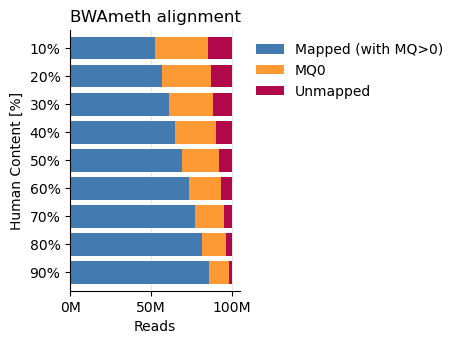

In [12]:
# MultiQC samtools colours, in column order: mapped (MQ>0), MQ0, unmapped
multiqc_colors = ["#437bb1", "#FF9933", "#b1084c"]


fig, ax = plt.subplots(figsize=mm_to_inches([120, 90]), facecolor="white")
ax.set_facecolor("white")

alignment_rates.plot(
    kind="barh",
    stacked=True,
    width=0.8,
    color=multiqc_colors[: alignment_rates.shape[1]],
    edgecolor="none",
    ax=ax,
)

ax.invert_yaxis()  # lowest percentage at the top
ax.set_xlabel("Reads")
ax.set_ylabel("Human Content [%]")
ax.set_title("BWAmeth alignment")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)

from matplotlib.ticker import FuncFormatter

ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x / 1e6:g}M"))
ax.set_xlabel("Reads")


ax.grid(axis="x", color="#e6e6e6", linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)

plt.tight_layout()
plt.savefig(
    fig_dir / "samtools_alignment_plot.pdf",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)